**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

* **NOMBRE:** Oliver Ulises Fajardo Calderón
* **MATRÍCULA:** A01610928

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Bibliotecas utilizadas en la actividad.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency
from sklearn.impute import SimpleImputer
from IPython.display import display

sns.set_theme(style="whitegrid")

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [2]:
# 1. Cargar datos; el id es identificador, no variable predictora.
cardio_df = pd.read_csv("heart_disease.csv", index_col="id")
print("Dimensiones iniciales:", cardio_df.shape)
cardio_df.info()

num_iniciales = cardio_df.select_dtypes(include="number").columns.tolist()
texto_iniciales = cardio_df.select_dtypes(include="object").columns.tolist()
print(f"Columnas numéricas: {len(num_iniciales)} -> {num_iniciales}")
print(f"Columnas de texto: {len(texto_iniciales)} -> {texto_iniciales}")
print("\nValores únicos por columna (sin contar NaN):")
display(cardio_df.nunique(dropna=True).to_frame("valores_unicos"))

Dimensiones iniciales: (918, 15)
<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB
Columnas numéricas: 7 -> ['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'num']
Columnas de texto: 8 -> ['sex', 'origin', 'cp', 'fbs'

,valores_unicos
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


**Respuesta 1.** La base contiene **918 observaciones** y, tras establecer `id` como índice, **15 variables**: **7 numéricas y 8 de texto**. Se imprimen los valores únicos de cada variable para reconocer posibles códigos categóricos.

2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [3]:
# 2. Detectar variables numéricas que en realidad codifican categorías.
print("Columnas numéricas con 10 o menos valores únicos:")
for columna in cardio_df.select_dtypes(include="number"):
    if cardio_df[columna].nunique(dropna=True) <= 10:
        print(columna, ":", sorted(cardio_df[columna].dropna().unique().tolist()))

# 'ca' es recuento ordinal (0-3), y 'num' es grado de enfermedad (0-4).
cardio_df["ca"] = pd.Categorical(cardio_df["ca"], categories=[0.0, 1.0, 2.0, 3.0], ordered=True)
cardio_df["num"] = pd.Categorical(cardio_df["num"], categories=[0, 1, 2, 3, 4], ordered=True)

# Variables nominales: no hay un orden cuantitativo natural entre sus clases.
for columna in cardio_df.select_dtypes(include="object").columns:
    cardio_df[columna] = cardio_df[columna].astype("category")

print("\nTipos de datos tras clasificar correctamente las variables:")
display(cardio_df.dtypes.to_frame("tipo"))

Columnas numéricas con 10 o menos valores únicos:
ca : [0.0, 1.0, 2.0, 3.0]
num : [0, 1, 2, 3, 4]

Tipos de datos tras clasificar correctamente las variables:


,tipo
age,int64
sex,category
origin,category
cp,category
trestbps,float64
chol,float64
fbs,category
restecg,category
thalch,float64
exang,category


**Respuesta 2.** Las únicas variables numéricas con pocos valores distintos son `ca` (recuento de vasos, valores de 0 a 3) y `num` (grado de enfermedad, de 0 a 4). Ambas se convierten a categorías **ordinales**, respetando el orden clínico de sus códigos. `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope` y `thal` son categorías nominales: sus valores no son magnitudes numéricas ordenables.

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [4]:
# 3. Descripciones para cada naturaleza de variable.
num_cols = cardio_df.select_dtypes(include="number").columns.tolist()
cat_cols = cardio_df.select_dtypes(include=["object", "category"]).columns.tolist()

resumen_num = cardio_df[num_cols].describe().T
resumen_num["asimetria"] = cardio_df[num_cols].skew()
resumen_num["exceso_curtosis"] = cardio_df[num_cols].kurt()
print("Estadísticas numéricas (pandas informa exceso de curtosis):")
display(resumen_num.round(3))

print("\nEstadísticas categóricas:")
display(cardio_df[cat_cols].describe().T)
for columna in cat_cols:
    print(f"\nFrecuencias de {columna}:")
    display(cardio_df[columna].value_counts(dropna=False).to_frame("frecuencia"))

Estadísticas numéricas (pandas informa exceso de curtosis):


,count,mean,std,min,25%,50%,75%,max,asimetria,exceso_curtosis
age,918.0,53.531,9.413,28.0,47.0,54.0,60.0,77.0,-0.194,-0.383
trestbps,859.0,132.295,18.536,80.0,120.0,130.0,140.0,200.0,0.630,0.633
chol,888.0,242.189,53.425,85.0,216.0,223.0,268.0,603.0,1.641,6.574
thalch,863.0,137.528,25.950,60.0,120.0,140.0,157.0,202.0,-0.209,-0.484
oldpeak,856.0,0.881,1.092,-2.6,0.0,0.5,1.5,6.2,1.038,1.120



Estadísticas categóricas:


,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411



Frecuencias de sex:


...

,frecuencia
ca,
NaN,609
0.0,181
1.0,67
2.0,41
3.0,20



Frecuencias de thal:


,frecuencia
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46



Frecuencias de num:


,frecuencia
num,
0,411
1,263
2,109
3,107
4,28


**Respuesta 3.** Para las variables numéricas se reportan las estadísticas descriptivas, el sesgo y el exceso de curtosis; las variables categóricas se describen mediante número de observaciones, categorías más frecuentes y tablas de frecuencia, incluyendo explícitamente los valores ausentes. Las variables ordinales no se resumen como si fuesen mediciones continuas.

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

,% faltante
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


Columnas eliminadas (>30% de ausencias): ['ca', 'thal', 'slope']


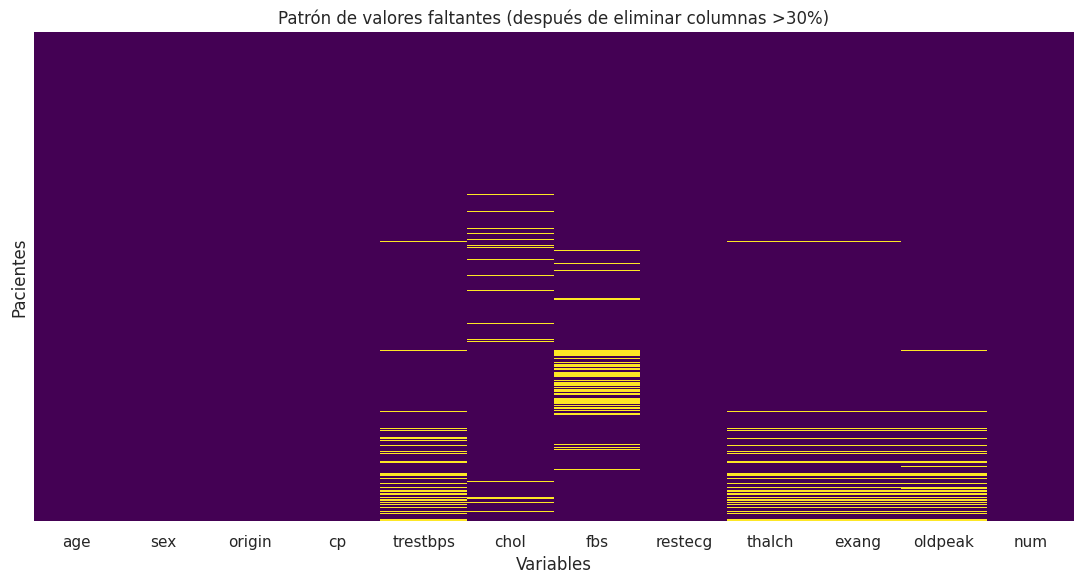


Cantidad de filas con dos variables faltantes simultáneamente:


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
age,0,0,0,0,0,0,0,0,0,0,0,0
sex,0,0,0,0,0,0,0,0,0,0,0,0
origin,0,0,0,0,0,0,0,0,0,0,0,0
cp,0,0,0,0,0,0,0,0,0,0,0,0
trestbps,0,0,0,0,59,3,1,0,55,55,55,0
chol,0,0,0,0,3,30,0,0,3,3,3,0
fbs,0,0,0,0,1,0,89,0,0,0,4,0
restecg,0,0,0,0,0,0,0,0,0,0,0,0
thalch,0,0,0,0,55,3,0,0,55,55,54,0
exang,0,0,0,0,55,3,0,0,55,55,54,0



En las filas sin 'thalch', cuántas tienen además otras variables faltantes:


,ausencias_concurrentes
thalch,55
exang,55
trestbps,55
oldpeak,54
chol,3
origin,0
sex,0
age,0
cp,0
fbs,0


In [5]:
# 4. Proporción de ausencias antes de descartar columnas.
porcentaje_nulos = cardio_df.isna().mean().mul(100).sort_values(ascending=False)
display(porcentaje_nulos.round(2).to_frame("% faltante"))

columnas_descartadas = porcentaje_nulos[porcentaje_nulos > 30].index.tolist()
print("Columnas eliminadas (>30% de ausencias):", columnas_descartadas)
cardio_df = cardio_df.drop(columns=columnas_descartadas)

# Matriz de ausencias con el identificador como índice.
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(cardio_df.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
ax.set_title("Patrón de valores faltantes (después de eliminar columnas >30%)")
ax.set_xlabel("Variables")
ax.set_ylabel("Pacientes")
plt.tight_layout()
plt.show()
plt.close(fig)

# Contar coausencias para las columnas restantes.
coausencias = cardio_df.isna().astype(int).T.dot(cardio_df.isna().astype(int))
print("\nCantidad de filas con dos variables faltantes simultáneamente:")
display(coausencias)

faltan_thalch = cardio_df["thalch"].isna()
print("\nEn las filas sin 'thalch', cuántas tienen además otras variables faltantes:")
display(cardio_df.loc[faltan_thalch].isna().sum().sort_values(ascending=False).to_frame("ausencias_concurrentes"))

**Respuesta 4.** Se eliminaron **`ca` (66.34%), `thal` (52.72%) y `slope` (33.55%)**, ya que superan estrictamente el umbral del 30% de ausencias. En el mapa de calor de las **12 variables restantes**, `thalch` y `exang` faltan juntos en **55 pacientes**; `trestbps` coincide en esos mismos 55 casos y `oldpeak` en **54**. `chol` sólo coincide en **3** de los 55. El patrón conjunto es compatible con episodios o registros en que no se obtuvo o cargó información cardiovascular de varias pruebas, especialmente las relacionadas con esfuerzo y angina. No demuestra por sí solo que las pruebas no se realizaran: también es posible una diferencia en protocolos, centros o transcripción de los registros. La American Heart Association describe que en las pruebas de esfuerzo se registran de forma relacionada frecuencia cardíaca, electrocardiograma, presión arterial y síntomas; ello aporta plausibilidad clínica al patrón de registros incompletos, sin determinar su causa exacta. **Referencia clínica:** American Heart Association (2025), [*Exercise Stress Test*](https://www.heart.org/en/health-topics/heart-attack/diagnosing-a-heart-attack/exercise-stress-test).

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [6]:
# Función auxiliar para la variable numérica; prueba t de Welch.
def Diagnose_MV_Numerical(df, col, faltan):
    observado = df.loc[~faltan, col].dropna()
    ausente = df.loc[faltan, col].dropna()
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.boxplot([observado, ausente], tick_labels=["thalch observado", "thalch faltante"],
               vert=False, showmeans=True)
    ax.set_xlabel(col)
    ax.set_title(f"{col}: grupos según ausencia de thalch")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    estadistico, p = ttest_ind(observado, ausente, equal_var=False)
    return {
        "variable": col,
        "media_observado": observado.mean(),
        "media_faltante": ausente.mean(),
        "n_observado": len(observado),
        "n_faltante": len(ausente),
        "prueba": "t de Welch",
        "estadistico": estadistico,
        "p_valor": p,
    }

In [7]:
# Función auxiliar para variables categóricas; prueba chi-cuadrada.
def Diagnose_MV_Categorical(df, col, faltan):
    tabla = pd.crosstab(df[col], faltan)
    tabla_porcentaje = tabla.div(tabla.sum(axis=1), axis=0).mul(100)
    fig, ax = plt.subplots(figsize=(7, 4))
    tabla_porcentaje.plot(kind="bar", stacked=True, ax=ax)
    ax.set_ylabel("Porcentaje dentro de categoría")
    ax.set_xlabel(col)
    ax.set_title(f"Ausencia de thalch según {col}")
    ax.legend(["Sin ausencia", "Con ausencia"], title="thalch")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
    chi2, p, dof, esperados = chi2_contingency(tabla)
    display(tabla)
    return {
        "variable": col,
        "prueba": "Chi-cuadrada",
        "estadistico": chi2,
        "p_valor": p,
        "gl": dof,
        "frecuencia_esperada_minima": esperados.min(),
    }

thalch faltante en 55 de 918 filas


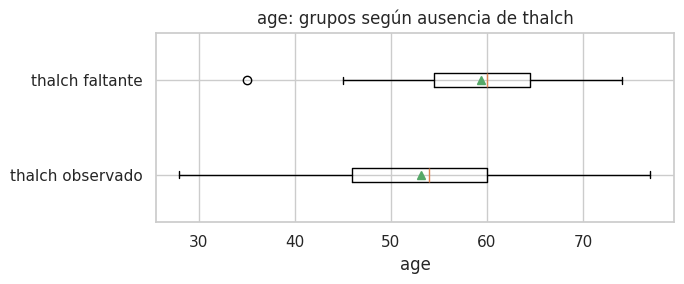

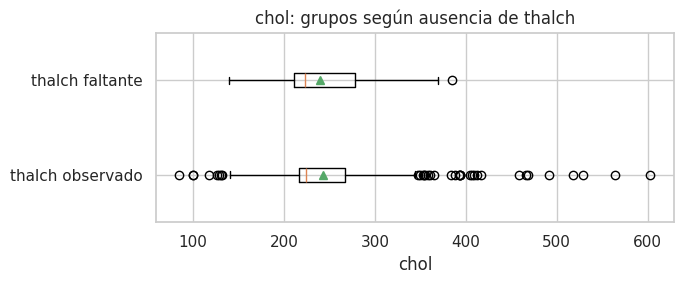

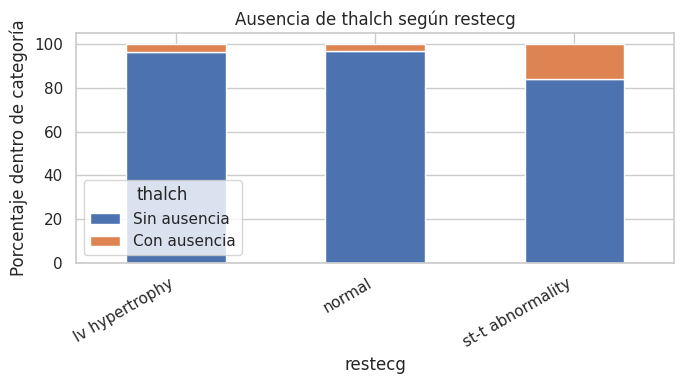

thalch,False,True
restecg,,
lv hypertrophy,181,7
normal,532,19
st-t abnormality,150,29


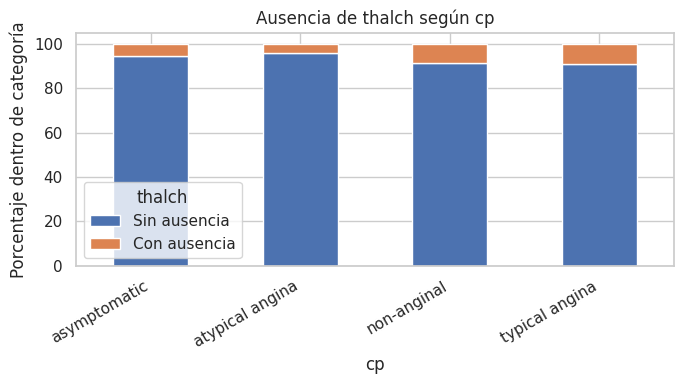

thalch,False,True
cp,,
asymptomatic,469,26
atypical angina,167,7
non-anginal,186,18
typical angina,41,4


Resultados de contrastes, H0 = no hay diferencias/asociación entre grupos:


,variable,media_observado,media_faltante,n_observado,n_faltante,prueba,estadistico,p_valor,gl,frecuencia_esperada_minima
0,age,53.155272,59.418182,863.0,55.0,t de Welch,-5.640020,0.000000,NaN,NaN
1,chol,242.351675,239.576923,836.0,52.0,t de Welch,0.373051,0.710472,NaN,NaN
2,restecg,NaN,NaN,NaN,NaN,Chi-cuadrada,41.171728,0.000000,2.0,10.724401
3,cp,NaN,NaN,NaN,NaN,Chi-cuadrada,5.252704,0.154201,3.0,2.696078



Porcentaje de thalch faltante por restecg:


,% thalch faltante
restecg,
lv hypertrophy,3.72
normal,3.45
st-t abnormality,16.20


In [8]:
# 5. Contrastamos los grupos antes de cualquier imputación.
# thalch es la grafía exacta del CSV y de la plantilla.
faltan_thalch = cardio_df["thalch"].isna()
print(f"thalch faltante en {faltan_thalch.sum()} de {len(cardio_df)} filas")

resultados_pruebas = []
for col in ["age", "chol"]:
    resultados_pruebas.append(Diagnose_MV_Numerical(cardio_df, col, faltan_thalch))
for col in ["restecg", "cp"]:
    resultados_pruebas.append(Diagnose_MV_Categorical(cardio_df, col, faltan_thalch))

resultados_pruebas_df = pd.DataFrame(resultados_pruebas)
print("Resultados de contrastes, H0 = no hay diferencias/asociación entre grupos:")
display(resultados_pruebas_df.round(6))

# Desglose adicional de la tasa de ausencia para fundamentar la interpretación.
print("\nPorcentaje de thalch faltante por restecg:")
display(cardio_df.groupby("restecg", observed=True)["thalch"].apply(lambda x: x.isna().mean() * 100).round(2).to_frame("% thalch faltante"))

**Respuesta 5.** Se contrasta la ausencia de `thalch` en **55 de 918 casos** con `age`, `chol`, `restecg` y `cp`, usando **t de Welch** (numéricas, comparación de medias) y **chi-cuadrada de independencia** (categóricas), junto con boxplots y barras relativas. Con α = 0.05, hay diferencias significativas para **`age`** (p ≈ 4.12 × 10⁻⁷; edades medias 59.42 frente a 53.16) y **`restecg`** (p ≈ 1.15 × 10⁻⁹). Para **`chol`** (p ≈ 0.710) y **`cp`** (p ≈ 0.154) no se encontró evidencia suficiente de asociación. En `restecg`, falta `thalch` en **16.20%** de los registros con anomalía ST-T frente a **3.45%** en ECG normal. Se **rechaza la hipótesis MCAR** para `thalch` por su asociación con variables observadas, y **MAR resulta más plausible** si la ausencia depende de esa información registrada. Estas pruebas *no permiten probar MAR ni descartar MNAR*; la confirmación exigiría conocer el proceso clínico o administrativo de recolección. Dada la coexistencia de faltantes, una explicación posible es la variación entre centros o protocolos de realización de pruebas, pero no se puede demostrar causalidad con estos datos.

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

Ausencias ANTES de la imputación por restecg:


,faltantes
trestbps,59
thalch,55
exang,55
oldpeak,62


Ausencias DESPUÉS de la imputación por restecg:


,faltantes
trestbps,0
thalch,0
exang,0
oldpeak,0


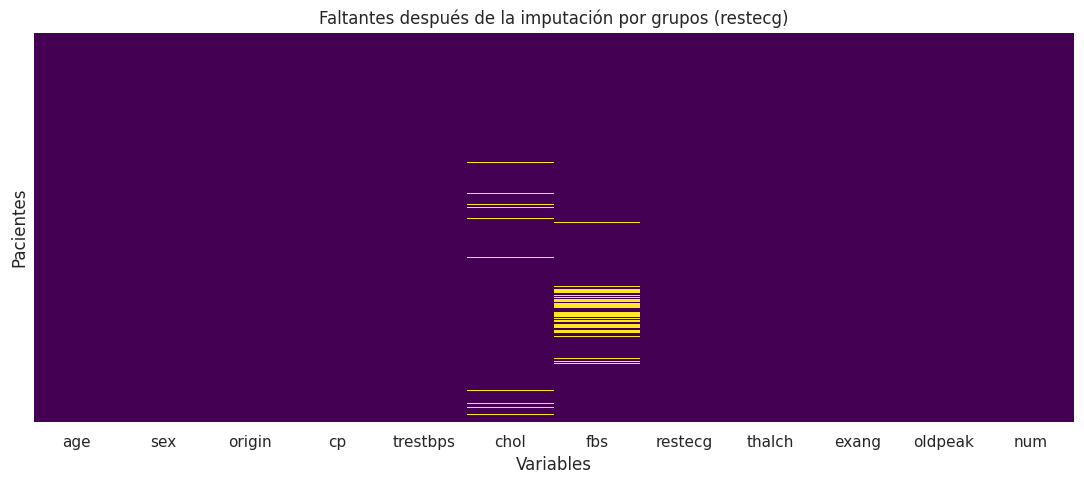

In [9]:
# 6. Imputación segmentada por el resultado del ECG en reposo.
# Variables con ausencias casi simultáneas a thalch: trestbps, thalch, exang y oldpeak.
variables_patron = ["trestbps", "thalch", "exang", "oldpeak"]

print("Ausencias ANTES de la imputación por restecg:")
display(cardio_df[variables_patron].isna().sum().to_frame("faltantes"))

# Variables cuantitativas: mediana de cada grupo, robusta ante sesgo y atípicos.
for columna in ["trestbps", "thalch", "oldpeak"]:
    valores_grupo = cardio_df.groupby("restecg", observed=True)[columna].transform("median")
    cardio_df[columna] = cardio_df[columna].fillna(valores_grupo)

# Variable nominal/boleana: moda de cada grupo, no mediana ni promedio.
modas_grupo = cardio_df.groupby("restecg", observed=True)["exang"].transform(
    lambda s: s.mode(dropna=True).iloc[0] if not s.mode(dropna=True).empty else np.nan
)
cardio_df["exang"] = cardio_df["exang"].fillna(modas_grupo)

print("Ausencias DESPUÉS de la imputación por restecg:")
display(cardio_df[variables_patron].isna().sum().to_frame("faltantes"))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(cardio_df.isna(), cbar=False, cmap="viridis", yticklabels=False, ax=ax)
ax.set_title("Faltantes después de la imputación por grupos (restecg)")
ax.set_xlabel("Variables")
ax.set_ylabel("Pacientes")
plt.tight_layout()
plt.show()
plt.close(fig)

**Respuesta 6.** Se agrupa por `restecg` y se imputan las variables con patrón de ausencia semejante al de `thalch`: **`thalch`, `exang`, `trestbps` y `oldpeak`**. Se usa la **mediana dentro de cada grupo** para medidas numéricas (`thalch`, `trestbps`, `oldpeak`), por su robustez ante valores extremos, y la **moda de cada grupo** para `exang`, variable nominal booleana. El segundo mapa de calor verifica que las ausencias correspondientes desaparecieron, sin modificar los valores observados.

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [10]:
# 7. Completar las ausencias restantes usando SimpleImputer (sin agrupar).
columnas_pendientes = cardio_df.columns[cardio_df.isna().any()].tolist()
registro_imputacion = []
for columna in columnas_pendientes:
    es_categorica = isinstance(cardio_df[columna].dtype, pd.CategoricalDtype) or cardio_df[columna].dtype == "object"
    estrategia = "most_frequent" if es_categorica else "median"
    imputador = SimpleImputer(strategy=estrategia)
    valores = cardio_df[[columna]].astype(object) if es_categorica else cardio_df[[columna]]
    imputados = imputador.fit_transform(valores).ravel()
    n_faltantes = int(cardio_df[columna].isna().sum())
    if es_categorica:
        cardio_df[columna] = pd.Categorical(
            imputados,
            categories=cardio_df[columna].cat.categories,
            ordered=cardio_df[columna].cat.ordered,
        )
    else:
        cardio_df[columna] = imputados
    registro_imputacion.append({
        "variable": columna,
        "tipo": "categórica" if es_categorica else "numérica",
        "estrategia": estrategia,
        "faltantes_imputados": n_faltantes,
        "valor_utilizado": str(imputador.statistics_[0]),
    })

print("Resumen de imputación global:")
display(pd.DataFrame(registro_imputacion))
print("Ausencias restantes:", int(cardio_df.isna().sum().sum()))
assert not cardio_df.isna().any().any(), "Quedan datos sin imputar; revisar las categorías."

Resumen de imputación global:


,variable,tipo,estrategia,faltantes_imputados,valor_utilizado
0,chol,numérica,median,30,223.0
1,fbs,categórica,most_frequent,89,False


Ausencias restantes: 0


**Respuesta 7.** Tras la imputación por grupos quedan faltantes en **`chol` (30)** y **`fbs` (89)**. La mediana calculada para `chol` fue **223 mg/dl**, y la moda para `fbs` fue **False**. Se utiliza `SimpleImputer(strategy="median")` para `chol`, ya que el colesterol presenta dispersión y posibles extremos, y `SimpleImputer(strategy="most_frequent")` para la categoría booleana `fbs`, ya que su media no representaría una categoría válida. El conjunto queda sin celdas faltantes. Estas sustituciones permiten completar el ejercicio, aunque implican pérdida de variabilidad y no sustituyen datos clínicos reales.

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

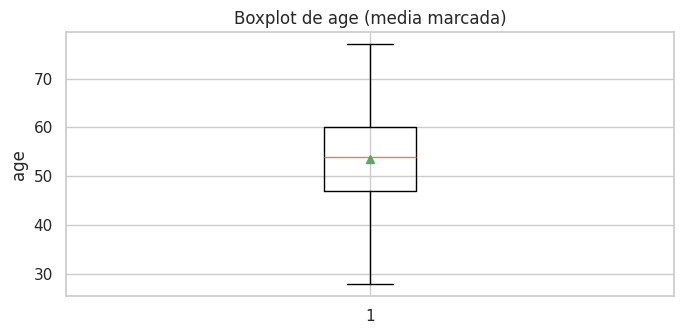

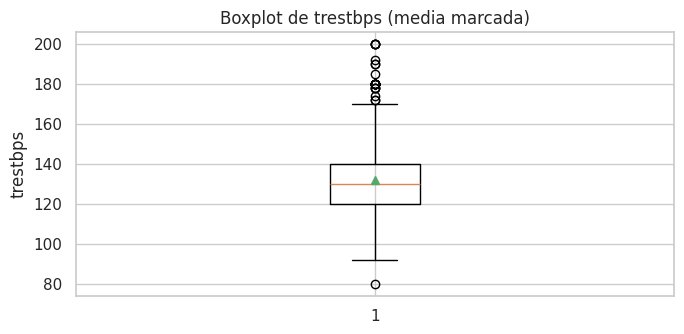

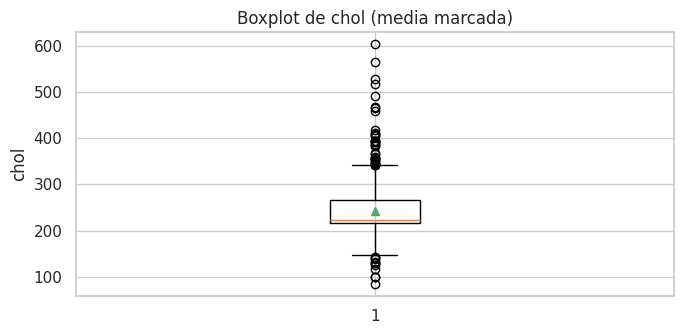

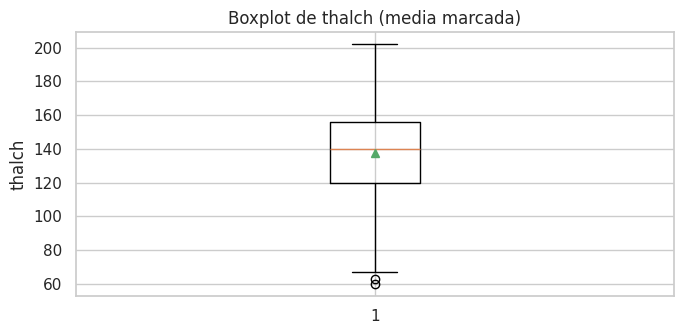

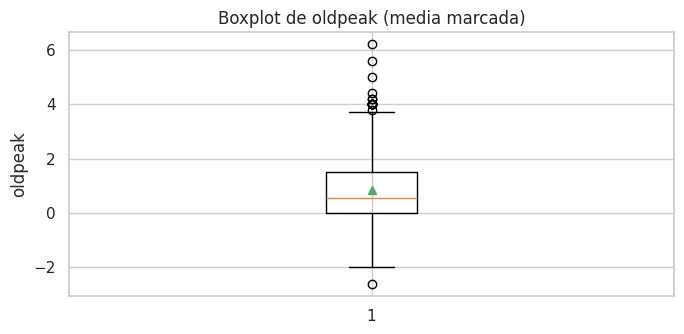

Valores atípicos detectados en el componente 'fliers' del boxplot:


,variable,cantidad_atipicos,valores_distintos
0,age,0,0
1,trestbps,27,9
2,chol,44,40
3,thalch,2,2
4,oldpeak,16,8


Atípicos gráficos de trestbps: [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]


In [11]:
# 8. Detección de atípicos con el objeto que devuelve Matplotlib.
num_cols_depuradas = cardio_df.select_dtypes(include="number").columns.tolist()
valores_atipicos_box = {}
resumen_atipicos = []

for columna in num_cols_depuradas:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    caja = ax.boxplot(cardio_df[columna].dropna(), showmeans=True)
    ax.set_title(f"Boxplot de {columna} (media marcada)")
    ax.set_ylabel(columna)
    atipicos = caja["fliers"][0].get_ydata()
    valores_atipicos_box[columna] = np.asarray(atipicos, dtype=float)
    resumen_atipicos.append({"variable": columna,
                             "cantidad_atipicos": len(atipicos),
                             "valores_distintos": np.unique(atipicos).size})
    plt.tight_layout()
    plt.show()
    plt.close(fig)

print("Valores atípicos detectados en el componente 'fliers' del boxplot:")
display(pd.DataFrame(resumen_atipicos))
print("Atípicos gráficos de trestbps:", np.sort(valores_atipicos_box["trestbps"]))

**Respuesta 8.** Se presentan boxplots individuales de todas las variables que continúan siendo **numéricas** (`age`, `trestbps`, `chol`, `thalch` y `oldpeak`). En cada caso los valores atípicos se extraen directamente del objeto gráfico mediante **`caja["fliers"][0].get_ydata()`**, y se resume su cantidad: **0** atípicos en `age`, **27** en `trestbps`, **44** en `chol`, **2** en `thalch` y **16** en `oldpeak`. Los puntos fuera de los bigotes son *candidatos atípicos según la regla gráfica de 1.5 × IQR*, no necesariamente errores de medición ni pacientes que deban descartarse de forma general.

9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [12]:
# 9. Regla intercuartílica, calculada sobre el mismo conjunto que el boxplot.
q1 = cardio_df["trestbps"].quantile(0.25)
q3 = cardio_df["trestbps"].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

mascara_outliers = (
    (cardio_df["trestbps"] < limite_inferior)
    | (cardio_df["trestbps"] > limite_superior)
)
outliers_iqr = cardio_df.loc[mascara_outliers, "trestbps"].to_numpy(dtype=float)
outliers_grafica = valores_atipicos_box["trestbps"]
coinciden = np.array_equal(np.sort(outliers_iqr), np.sort(outliers_grafica))

print(f"Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}")
print(f"Límite inferior={limite_inferior:.2f}; límite superior={limite_superior:.2f}")
print("Atípicos IQR:", len(outliers_iqr), "; valores:", np.sort(outliers_iqr))
print("¿Coinciden con los del boxplot?:", coinciden)
display(cardio_df.loc[mascara_outliers, ["age", "trestbps", "chol", "thalch", "num"]])
assert coinciden, "La regla IQR y la extracción gráfica deberían coincidir."

Q1=120.00; Q3=140.00; IQR=20.00
Límite inferior=90.00; límite superior=170.00
Atípicos IQR: 27 ; valores: [ 80. 172. 172. 174. 178. 178. 178. 180. 180. 180. 180. 180. 180. 180.
 180. 180. 180. 180. 180. 185. 190. 190. 192. 200. 200. 200. 200.]
¿Coinciden con los del boxplot?: True


,age,trestbps,chol,thalch,num
id,,,,,
15,52,172.0,199.0,162.0,0
84,68,180.0,274.0,150.0,3
127,56,200.0,288.0,133.0,3
173,59,174.0,249.0,143.0,1
184,59,178.0,270.0,145.0,0
189,54,192.0,283.0,195.0,1
202,64,180.0,325.0,154.0,0
214,66,178.0,228.0,165.0,3
232,55,180.0,327.0,117.0,2


**Respuesta 9.** Se obtuvieron **Q1 = 120 mm Hg**, **Q3 = 140 mm Hg** e **IQR = 20 mm Hg**, lo que produce límites de **90 y 170 mm Hg**, mediante **Q1 − 1.5 × IQR** y **Q3 + 1.5 × IQR**. Se comparan los valores y las frecuencias de los registros fuera de estos límites con los puntos `fliers` del boxplot del ejercicio 8; ambos métodos coincidieron exactamente en **27 registros** porque se basan en la misma regla. La comparación se realiza sobre las observaciones **ya imputadas**, de forma consistente entre ambas técnicas.

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

Filas antes: 918
Registros eliminados: 27
Filas finales: 891


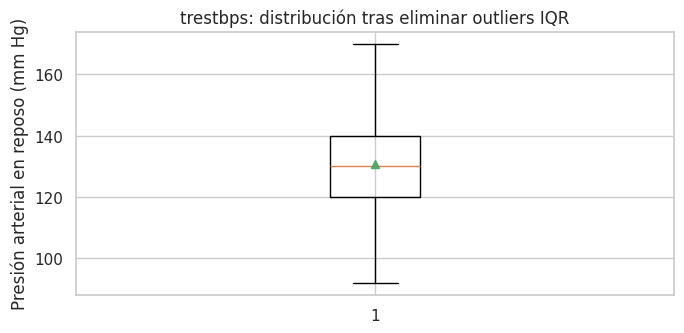

Valores faltantes en el dataframe final: 0


In [13]:
# 10. Eliminar filas fuera de los límites identificados en el ejercicio 9.
filas_antes = len(cardio_df)
cardio_df = cardio_df.loc[~mascara_outliers].copy()
print("Filas antes:", filas_antes)
print("Registros eliminados:", filas_antes - len(cardio_df))
print("Filas finales:", len(cardio_df))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot(cardio_df["trestbps"], showmeans=True)
ax.set_title("trestbps: distribución tras eliminar outliers IQR")
ax.set_ylabel("Presión arterial en reposo (mm Hg)")
plt.tight_layout()
plt.show()
plt.close(fig)
print("Valores faltantes en el dataframe final:", int(cardio_df.isna().sum().sum()))

**Respuesta 10.** Se eliminaron **27 registros** y el dataset final quedó con **891 pacientes**, sin valores faltantes. Se descartan **sólo** las filas de `trestbps` identificadas como atípicas en el paso 9 y se genera un boxplot final de esa variable. En datos clínicos, las presiones extremas podrían ser verdaderas y relevantes; aquí se eliminan exclusivamente porque así lo requiere la consigna del ejercicio, no como recomendación de práctica médica universal.

---

**Declaración de uso de inteligencia artificial**

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje grande]. Se utilizó como apoyo en la generación, revisión, depuración y optimización del código en Python, así como en la estructuración e interpretación estadística de los resultados. https://chatgpt.com/

La revisión de los resultados, la correcta interpretación y la responsabilidad final de la entrega corresponden al autor.

---